**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**01 | Original GazeBase Data and Participant-Disjoint Protocol**

![Five-band schematic of the executed 100-person source-preparation pipeline](../../images/01_data_and_experimental_protocol.svg)

**Objective:** Prepare one source-identifiable, participant-disjoint dataset for four-class GazeBase task recognition (FXS, HSS, RAN and TEX). The target is the **recording protocol**, not cognitive state, reading comprehension or a clinical outcome.

**Recorded execution:** The Round 1 / Session 1 run successfully selected **100 people**, each with all four task files, from source IDs **1001–1108**. Eight unavailable or incomplete IDs were skipped. This yielded **400 original recordings**, **400 record-feature rows** and **9,600 temporal windows**, each with 256 samples and four motion channels.

**Evaluation design:** Participant-level Train / Validation / Test groups contain **64 / 16 / 20 people**. Train-only normalisation is retained. This notebook prepares modelling inputs; subsequent notebooks fit the models, select a primary candidate using Validation and evaluate the held-out Test.

**Data provenance:** The original GazeBase v2.0 archive was checked and selectively extracted. Derived stage outputs contain source identities, features, split assignments and temporal windows rather than another copy of the original archive.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# ------------------------ 2. Read-Only Source Adapter ------------------------
import sys
source_module = str(root / "eye_tracking_foundations" / "code" / "src")
if source_module not in sys.path:
    sys.path.insert(0, source_module)

# ----------------------- 3. Scientific Data Libraries ------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# -------------------------- 4. Modelling Utilities ---------------------------
from gaze_source import discover_records
from s2_data import (
    TASKS, CHANNELS, FEATURES, participant_split,
    build_source_tables, normalise_train_only, save_protocol,
)

# ----------------------------- 5. Output Folder ------------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100, figure_size=(9, 4))
print("Project output directory:", output_dir)
print("Shared original GazeBase source:", root / "data" / "raw" / "gazebase")


Repository up to date.
Project output directory: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output
Shared original GazeBase source: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/gazebase


**02. Configure, Acquire and Select Original GazeBase Recordings**

The configuration cell sets `MAX_PARTICIPANTS = 100`, seed 17, the fixed Round 1 / Session 1 source boundary, and the approved window and split settings. The acquisition step verified the published source archive and selected the **first 100 complete people in source-ID order**, rather than assuming 100 consecutive identifiers.

**Observed source selection:** IDs **1028, 1036, 1050, 1056, 1075, 1082, 1104 and 1105** were unavailable or incomplete for the required four-file set. The selection continued through **1108**, retaining exactly 100 people and **100 recordings per task**. All 400 selected files passed the existing nonempty/valid-sample check, and the source audit reported **zero non-increasing timestamp transitions**.

Across the four tasks, mean valid-sample fractions were approximately **0.960 (FXS)**, **0.964 (HSS)**, **0.970 (RAN)** and **0.947 (TEX)**. The lowest individual source-record fraction was approximately **0.478**. These are source-quality descriptions, not a new eligibility threshold or evidence that all recordings have identical quality.

The verified archive was removed after successful extraction and quality inspection, while selected original CSVs remained local to that Colab Runtime. `01_source_acquisition_preflight.csv` and `01_source_acquisition_task_summary.csv` retain the observed source audit. Changing the cohort or selection rule defines a separate experiment; the recorded 100-person Test was evaluated downstream.


In [3]:
# ======================= 02. Main-Cohort Configuration =======================

# ---------------------------- 1. Research Cohort -----------------------------
MAX_PARTICIPANTS = 100         # Single edit for 100, 300, etc.
FIRST_SOURCE_ID = 1001        # Round 1 identifier sequence
SEED = 17
TEST_FRACTION = 0.20         # Of all selected people
VALIDATION_FRACTION = 0.20   # Of non-Test people

# ------------------------ 2. Temporal Input Protocol -------------------------
WINDOW_SAMPLES = 256
MAX_WINDOWS_PER_RECORD = 24

# --------------------------- 3. Validate Selection ---------------------------
if not 10 <= MAX_PARTICIPANTS <= 322:
    raise ValueError("Round 1 supports a maximum of 322 source people.")
if FIRST_SOURCE_ID != 1001:
    raise ValueError("This experiment uses Round 1 source IDs from 1001.")
if not (0 < TEST_FRACTION < 0.5 and 0 < VALIDATION_FRACTION < 0.5):
    raise ValueError("Split fractions must be between zero and 0.5.")
print("Requested complete participants:", MAX_PARTICIPANTS)
print("Starting source ID:", FIRST_SOURCE_ID)
print("Required original recordings:", 4 * MAX_PARTICIPANTS)
print("Actual source IDs will be selected from eligible archive records.")


Requested complete participants: 100
Starting source ID: 1001
Required original recordings: 400
Actual source IDs will be selected from eligible archive records.


In [4]:
# ==================== 02. Acquire Original GazeBase CSVs =====================

# ------------------------ 1. Select Original Sources -------------------------
from s2_acquisition import ensure_gazebase_cohort_preflight

source_dir = root / "data" / "raw" / "gazebase"
source_audit = ensure_gazebase_cohort_preflight(
    raw_root=source_dir,
    download_root=Path("/content") / "gazebase_source_download",
    output_csv=output_dir / "01_source_acquisition_preflight.csv",
    participants=MAX_PARTICIPANTS,
    first_source_id=FIRST_SOURCE_ID,
)
SOURCE_AUDIT_IDS = tuple(sorted(source_audit.source_id.unique()))
print("Selected source IDs:", SOURCE_AUDIT_IDS)

# -------------------------- 2. Audit Task Coverage ---------------------------
task_summary = source_audit.groupby("task", sort=True).agg(
    n_records=("record_id", "size"),
    n_people=("source_id", "nunique"),
    n_samples=("n_samples", "sum"),
    mean_valid_fraction=("valid_fraction", "mean"),
    source_size_bytes=("n_bytes", "sum"),
).reset_index()
task_summary.to_csv(
    output_dir / "01_source_acquisition_task_summary.csv", index=False,
)

# ---------------------------- 3. Inspect Sources -----------------------------
if source_audit.source_id.nunique() != MAX_PARTICIPANTS:
    raise ValueError("Source audit does not cover the requested people")
print("Source participants audited:", source_audit.source_id.nunique())
print("Source recordings audited:", len(source_audit))
print("Source directory:", source_dir)
display(task_summary)
display(source_audit.head(8))


Download source 1/4 (official Figshare): https://ndownloader.figshare.com/files/27039812
Downloaded 1.0 GB.
Downloaded 2.0 GB.
Downloaded 3.0 GB.
Downloaded 4.0 GB.
Downloaded 5.0 GB.
Downloaded 6.0 GB.
Verifying archive length and official published MD5...
Verified GazeBase archive ready for selective extraction.
Selected 100 complete source people (IDs 1001–1108).
Unavailable/incomplete IDs skipped: [1028, 1036, 1050, 1056, 1075, 1082, 1104, 1105]
Recovering 360 selected original CSVs.
Selected source IDs: (np.int64(1001), np.int64(1002), np.int64(1003), np.int64(1004), np.int64(1005), np.int64(1006), np.int64(1007), np.int64(1008), np.int64(1009), np.int64(1010), np.int64(1011), np.int64(1012), np.int64(1013), np.int64(1014), np.int64(1015), np.int64(1016), np.int64(1017), np.int64(1018), np.int64(1019), np.int64(1020), np.int64(1021), np.int64(1022), np.int64(1023), np.int64(1024), np.int64(1025), np.int64(1026), np.int64(1027), np.int64(1029), np.int64(1030), np.int64(1031), np.in

,task,n_records,n_people,n_samples,mean_valid_fraction,source_size_bytes
0,FXS,100,100,1507864,0.960104,81222310
1,HSS,100,100,10132594,0.963528,564404961
2,RAN,100,100,10111342,0.969522,542905393
3,TEX,100,100,6024366,0.947016,254749327


,source_id,record_id,task,n_bytes,n_samples,valid_fraction,nonincreasing_time_steps
0,1001,S_1001_S1_FXS,FXS,804400,15077,0.967566,0
1,1001,S_1001_S1_HSS,HSS,5614539,101299,0.996387,0
2,1001,S_1001_S1_RAN,RAN,5356668,101204,0.986779,0
3,1001,S_1001_S1_TEX,TEX,2503454,60233,0.966713,0
4,1002,S_1002_S1_FXS,FXS,795789,15074,0.968356,0
5,1002,S_1002_S1_HSS,HSS,5611695,101313,0.990959,0
6,1002,S_1002_S1_RAN,RAN,5369372,101299,0.990869,0
7,1002,S_1002_S1_TEX,TEX,2529272,60237,0.985557,0


In [5]:
# ================== 02. Select Original GazeBase Recordings ==================

# ------------------------ 1. User-Facing Cohort Size -------------------------
source_dir = root / "data" / "raw" / "gazebase"

# ----------------------- 2. Discover Complete Records ------------------------
inventory = discover_records(
    source_dir, round_id=1, session_id=1,
    tasks=TASKS, max_participants=322,
)
# Select precisely the people audited above, not merely the first N local
# filenames, since other tasks or historical source CSVs may be present.
selected_people = {f"{sid % 1000:03d}" for sid in SOURCE_AUDIT_IDS}
inventory = inventory.loc[
    inventory.participant_id.isin(selected_people)
].copy()
actual_people = inventory["participant_id"].nunique()
if actual_people != MAX_PARTICIPANTS:
    raise ValueError(
        f"Requested {MAX_PARTICIPANTS} complete participants but only "
        f"{actual_people} are available. Add authorised GazeBase source CSVs "
        "before increasing the cohort size."
    )
inventory.drop(columns=["path"]).to_csv(
    output_dir / "01_source_inventory.csv", index=False,
)
if set(inventory.record_id) != set(source_audit.record_id):
    raise ValueError("Source inventory differs from the audited cohort")
print("Complete participants:", actual_people)
print("Original task recordings:", len(inventory))
print("Source task labels:", sorted(inventory.task.unique()))
display(inventory[["record_id", "participant_id", "task", "relative_file"]].head(12))


Complete participants: 100
Original task recordings: 400
Source task labels: ['FXS', 'HSS', 'RAN', 'TEX']


,record_id,participant_id,task,relative_file
0,S_1001_S1_FXS,001,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...
1,S_1001_S1_HSS,001,HSS,GazeBase_v2_0/Round_1/Subject_1001/S1_Horizont...
2,S_1001_S1_RAN,001,RAN,GazeBase_v2_0/Round_1/Subject_1001/S1_Random_S...
3,S_1001_S1_TEX,001,TEX,GazeBase_v2_0/Round_1/Subject_1001/S1_Reading/...
4,S_1002_S1_FXS,002,FXS,GazeBase_v2_0/Round_1/Subject_1002/S1_Fixation...
5,S_1002_S1_HSS,002,HSS,GazeBase_v2_0/Round_1/Subject_1002/S1_Horizont...
6,S_1002_S1_RAN,002,RAN,GazeBase_v2_0/Round_1/Subject_1002/S1_Random_S...
7,S_1002_S1_TEX,002,TEX,GazeBase_v2_0/Round_1/Subject_1002/S1_Reading/...
8,S_1003_S1_FXS,003,FXS,GazeBase_v2_0/Round_1/Subject_1003/S1_Fixation...
9,S_1003_S1_HSS,003,HSS,GazeBase_v2_0/Round_1/Subject_1003/S1_Horizont...


**03. Register Participant-Disjoint Train, Validation and Test**

The executed seed-17 partition assigned whole people, keeping all four source tasks from any person in the **same split**:

| Partition | Independent people | Source recordings | Temporal windows |
| --- | ---: | ---: | ---: |
| Train | 64 | 256 | 6,144 |
| Validation | 16 | 64 | 1,536 |
| Reserved Test | 20 | 80 | 1,920 |

The highest 20 eligible source IDs were reserved for Test. The remaining people were divided into Train and Validation, with Validation comprising 20% of the development pool. Source identities agree across the recorded inventory, split and feature tables; no participant appears in more than one partition. **Test recordings were not used for training or model selection.** The subsequent held-out evaluation is reported in Notebook 05.


In [6]:
# ================= 03. Assign Independent Participant Groups =================

# ------------------------- 1. Frozen Split Registry --------------------------
split = participant_split(
    inventory, seed=SEED, test_fraction=TEST_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)
split.to_csv(output_dir / "01_split_assignments.csv", index=False)

# ------------------------ 2. Verify and Display Scope ------------------------
print("Study purpose:", split.study_purpose.iloc[0])
print("Independent people per partition:")
display(split.groupby("split").agg(
    n_people=("participant_id", "nunique"),
    n_task_records=("record_id", "count"),
).reset_index())
print("Participant sets:")
for role in ("train", "validation", "test"):
    people = sorted(split.loc[split.split.eq(role), "participant_id"].unique())
    print(role, ":", people)


Study purpose: main
Independent people per partition:


,split,n_people,n_task_records
0,test,20,80
1,train,64,256
2,validation,16,64


Participant sets:
train : ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '013', '014', '015', '017', '018', '019', '022', '023', '025', '026', '029', '030', '031', '034', '035', '037', '039', '040', '041', '042', '043', '044', '045', '046', '047', '049', '051', '053', '055', '057', '058', '059', '060', '061', '062', '064', '065', '066', '067', '068', '069', '070', '071', '073', '074', '076', '077', '078', '079', '080', '081', '084', '085']
validation : ['012', '016', '020', '021', '024', '027', '032', '033', '038', '048', '052', '054', '063', '072', '083', '086']
test : ['087', '088', '089', '090', '091', '092', '093', '094', '095', '096', '097', '098', '099', '100', '101', '102', '103', '106', '107', '108']


**04. Build Record Features and Contiguous Motion Windows**

This execution generated **400 feature rows**, one per original task recording, using the nine existing gaze summaries (including valid fraction, position dispersion, step/speed statistics and available pupil measures). It also generated **9,600 windows** of shape `(256, 4)`.

Every selected recording yielded the configured maximum of **24 non-overlapping windows**. Window construction respects original sample validity and permitted timing gaps; the resulting window counts are limited by the sampling cap and are **not** a guarantee of complete temporal coverage of each source recording.

The recorded 95th-percentile speed summary varies by source; isolated large values warrant descriptive quality review but do not justify changing a previously fixed feature definition after inspecting model outcomes. Source identifiers remain available for record-level aggregation in downstream notebooks.


In [ ]:
# ================== 04. Construct Gaze Features and Windows ==================

# --------------------- 1. Process Original Source Files ----------------------
record_features, windows, window_record_ids, window_labels = (
    build_source_tables(
        inventory, split, window_samples=WINDOW_SAMPLES,
        max_windows_per_record=MAX_WINDOWS_PER_RECORD,
    )
)
record_features.to_csv(output_dir / "01_record_features.csv", index=False)

# ------------------------- 2. Show Input Dimensions --------------------------
print("Source feature rows:", len(record_features))
print("Temporal windows / samples / channels:", windows.shape)
print("Raw temporal channels:", CHANNELS)
display(record_features[[
    "record_id", "participant_id", "task", "split",
    "valid_fraction", "n_windows", "speed_p95_dva_s",
]].head(12))


Source feature rows: 400
Temporal windows / samples / channels: (9600, 256, 4)
Raw temporal channels: ('relative_x_dva', 'relative_y_dva', 'delta_x_dva', 'delta_y_dva')


,record_id,participant_id,task,split,valid_fraction,n_windows,speed_p95_dva_s
0,S_1001_S1_FXS,001,FXS,train,0.967566,24,23.710742
1,S_1001_S1_HSS,001,HSS,train,0.996387,24,334.517138
2,S_1001_S1_RAN,001,RAN,train,0.986779,24,108.202030
3,S_1001_S1_TEX,001,TEX,train,0.966713,24,149.099253
4,S_1002_S1_FXS,002,FXS,train,0.968356,24,33.517744
5,S_1002_S1_HSS,002,HSS,train,0.990959,24,346.461856
6,S_1002_S1_RAN,002,RAN,train,0.990869,24,101.349886
7,S_1002_S1_TEX,002,TEX,train,0.985557,24,128.550220
8,S_1003_S1_FXS,003,FXS,train,0.986599,24,15.018685
9,S_1003_S1_HSS,003,HSS,train,0.997424,24,308.394018


**05. Fit Temporal Normalisation on Training Participants Only**

Four-channel means and scales were estimated from the **6,144 Train windows only** and applied unchanged to the **1,536 Validation** and **1,920 Test** windows. The recorded archive contains `9,600 × 256 × 4` normalised values, stored alongside source-record IDs and window labels.

The saved `01_sequence_normalisation.csv` provides the actual Train-derived moments. No Validation or Test sample contributes to fitting these statistics. The compressed `01_sequence_windows.npz` is approximately **19.7 MB**, below the current 50,000,000-byte per-file Git limit.


In [8]:
# ==================== 05. Train-Only Motion Normalisation ====================

# ------------------------ 1. Calculate Train Moments -------------------------
scaled, centre, scale = normalise_train_only(
    windows, window_record_ids, split,
)
np.savez_compressed(
    output_dir / "01_sequence_windows.npz",
    x=scaled, y=window_labels, record_id=window_record_ids,
)
pd.DataFrame({
    "channel": CHANNELS, "train_mean": centre, "train_scale": scale,
}).to_csv(output_dir / "01_sequence_normalisation.csv", index=False)

# ------------------------- 2. Show Train Statistics --------------------------
print("Normalised windows:", scaled.shape)
display(pd.DataFrame({
    "channel": CHANNELS, "train_mean": centre, "train_scale": scale,
}))
print("No Validation or Test examples were fitted during normalisation.")


Normalised windows: (9600, 256, 4)


,channel,train_mean,train_scale
0,relative_x_dva,-0.000850,3.503364
1,relative_y_dva,-0.034385,1.246911
2,delta_x_dva,0.000640,0.161946
3,delta_y_dva,0.001079,0.082554


No Validation or Test examples were fitted during normalisation.


**06. Save the Protocol and Source Distribution**

The executed protocol records the **100 selected source IDs**, start/end IDs 1001/1108, seed 17, Round 1 / Session 1, four task labels, the 64/16/20 person split rule, and the 256-sample / 24-window representation. This is saved in the current `01_protocol.csv`, not the obsolete ten-person JSON configuration.

The generated `01_source_distribution.png` shows the **observed counts by task and participant group**. The five-band figure above now reflects the executed 100-person source-preparation stage while retaining the original measured x/y source excerpt.


,Setting
dataset,GazeBase_v2_0
round_id,1
session_id,1
task_labels,"[FXS, HSS, RAN, TEX]"
max_participants,100
split_seed,17
window_samples,256
max_windows_per_record,24
test_fraction,0.2
validation_fraction_in_development,0.2


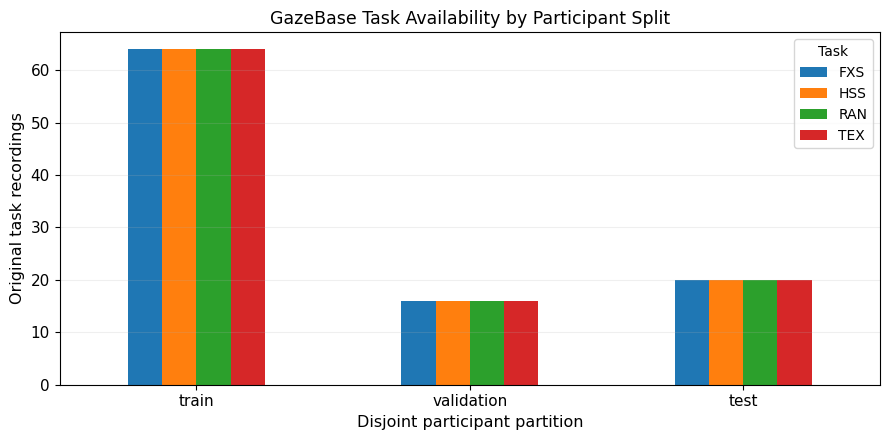

In [9]:
# =================== 06. Save Protocol and Source Overview ===================

# -------------------- 1. Record Explicit Scientific Setup --------------------
protocol = save_protocol(
    output_dir / "01_protocol.csv",
    participants=MAX_PARTICIPANTS, seed=SEED,
    window_samples=WINDOW_SAMPLES,
    max_windows_per_record=MAX_WINDOWS_PER_RECORD,
    purpose=split.study_purpose.iloc[0],
    test_fraction=TEST_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    source_first_id=FIRST_SOURCE_ID,
    selected_source_ids=SOURCE_AUDIT_IDS,
)
display(pd.Series(protocol, name="Setting").to_frame())

# ---------------------- 2. Visualise Independent Units -----------------------
counts = split.groupby(["split", "task"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
counts.reindex(["train", "validation", "test"]).plot(
    kind="bar", ax=ax, rot=0,
)
ax.set(xlabel="Disjoint participant partition",
       ylabel="Original task recordings",
       title="GazeBase Task Availability by Participant Split")
ax.legend(title="Task")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "01_source_distribution.png")
plt.show()


**07. Validate and Export the Stage-01 Evidence**

All **nine required stage-owned outputs** were present and packaged into `eye_movement_modelling_Notebook_01_Outputs.zip`: source inventory, split assignments, record features, temporal windows, normalisation, protocol, source-distribution figure, source preflight and task summary. The original ~6.7-GB archive and raw CSVs are not part of this transfer package.

**Downstream use:** Notebook 02 uses `01_record_features.csv`, `01_split_assignments.csv` and `01_protocol.csv` for classical baselines. Notebooks 03–04 use the normalised temporal windows for CNN, TCN, GRU and Transformer. Notebook 05 performs the Validation-based model selection and reports held-out Test results.


In [10]:
# ====================== 07. Export Current Notebook 01 =======================

# ---------------------- 1. Check Complete Stage Outputs ----------------------
required_outputs = (
    "01_source_inventory.csv",
    "01_split_assignments.csv",
    "01_record_features.csv",
    "01_sequence_windows.npz",
    "01_sequence_normalisation.csv",
    "01_protocol.csv",
    "01_source_distribution.png",
    "01_source_acquisition_preflight.csv",
    "01_source_acquisition_task_summary.csv",
)
missing_outputs = [
    filename for filename in required_outputs
    if not (output_dir / filename).is_file()
]
if missing_outputs:
    raise FileNotFoundError(
        "Notebook 01 stage outputs are incomplete: "
        f"{missing_outputs}. Execute the preceding cells first."
    )

# ----------------------- 2. Git Size Policy Inspection -----------------------
for filename in required_outputs:
    n_bytes = (output_dir / filename).stat().st_size
    if n_bytes > 50_000_000:
        print(f"Keep outside Git: {filename} ({n_bytes:,} bytes)")

# -------------------------- 3. Export Stage-01 ZIP ---------------------------
download_outputs_from_colab("eye_movement_modelling/output", "01")


------------------------------------------------------------------------
Notebook 01
Files packaged: 9
  + 01_protocol.csv
  + 01_record_features.csv
  + 01_sequence_normalisation.csv
  + 01_sequence_windows.npz
  + 01_source_acquisition_preflight.csv
  + 01_source_acquisition_task_summary.csv
  + 01_source_distribution.png
  + 01_source_inventory.csv
  + 01_split_assignments.csv
Download ZIP from Colab Contents: /content/eye_movement_modelling_Notebook_01_Outputs.zip
